In [1]:
#importing libraries
import sys
sys.path.append("..")

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data_loader import PROCESSED_DIR
from src.preprocessing import build_preprocessor
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, cross_val_predict
from sklearn.metrics import (average_precision_score, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay,
                             PrecisionRecallDisplay, precision_score, recall_score)

In [2]:
#loading train data and patient ids
X_train = pd.read_parquet(PROCESSED_DIR / "X_train.parquet")
y_train = pd.read_parquet(PROCESSED_DIR / "y_train.parquet")["readmitted_30"]
groups_train = pd.read_parquet(PROCESSED_DIR / "groups_train.parquet")["patient_nbr"]
print(X_train.shape, y_train.shape, groups_train.shape)

(69613, 44) (69613,) (69613,)


In [3]:
#building the baseline pipeline
baseline = Pipeline([
    ("pre", build_preprocessor()),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000)),
])
baseline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('encode', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_est

In [4]:
#setting up 5 grouped folds
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

In [5]:
#checking each fold
for fold, (tr_idx, va_idx) in enumerate(cv.split(X_train, y_train, groups_train), start=1):
    same_patients = len(set(groups_train.iloc[tr_idx]) & set(groups_train.iloc[va_idx]))
    print("fold", fold, "train:", len(tr_idx), "validation:", len(va_idx),
          "positive rate:", round(y_train.iloc[va_idx].mean(), 3), "patients in both:", same_patients)

fold 1 train: 55688 validation: 13925 positive rate: 0.114 patients in both: 0
fold 2 train: 55690 validation: 13923 positive rate: 0.114 patients in both: 0
fold 3 train: 55692 validation: 13921 positive rate: 0.114 patients in both: 0
fold 4 train: 55691 validation: 13922 positive rate: 0.114 patients in both: 0
fold 5 train: 55691 validation: 13922 positive rate: 0.114 patients in both: 0


In [6]:
#cross validating the baseline
scoring = ["average_precision", "recall", "precision", "f1"]
scores = cross_validate(baseline, X_train, y_train, groups=groups_train, cv=cv, scoring=scoring, n_jobs=-1)

fold_scores = pd.DataFrame({m: scores["test_" + m] for m in scoring})
fold_scores.round(3)

,average_precision,recall,precision,f1
0,0.206,0.525,0.177,0.265
1,0.210,0.538,0.181,0.271
2,0.206,0.545,0.181,0.271
3,0.217,0.572,0.185,0.280
4,0.224,0.555,0.189,0.282


In [7]:
#averaging scores across folds
fold_scores.agg(["mean", "std"]).round(3)

,average_precision,recall,precision,f1
mean,0.213,0.547,0.182,0.274
std,0.008,0.018,0.005,0.007


In [8]:
#out of fold probabilities
proba = cross_val_predict(baseline, X_train, y_train, groups=groups_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
pred = (proba >= 0.5).astype(int)

results = pd.DataFrame({"actual": y_train, "probability": proba.round(3), "predicted": pred})
results.head(10)

,actual,probability,predicted
encounter_id,,,
149190,0,0.475,0
64410,0,0.461,0
500364,0,0.464,0
16680,0,0.451,0
35754,0,0.410,0
55842,0,0.347,0
12522,0,0.454,0
15738,0,0.634,1
28236,0,0.451,0


[[42305 19393]
 [ 3588  4327]]


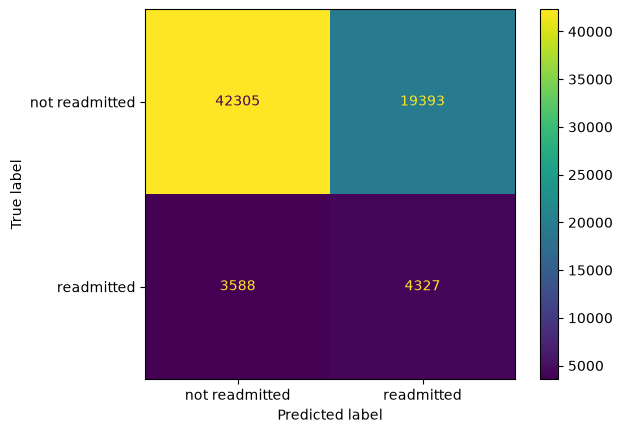

In [9]:
#confusion matrix at 0.5
print(confusion_matrix(y_train, pred))
ConfusionMatrixDisplay.from_predictions(y_train, pred, display_labels=["not readmitted", "readmitted"])
plt.show()

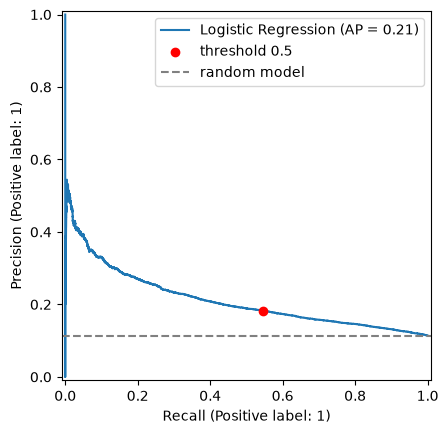

In [10]:
#precision recall curve with the 0.5 point
PrecisionRecallDisplay.from_predictions(y_train, proba, name="Logistic Regression")
plt.scatter(recall_score(y_train, pred), precision_score(y_train, pred), color="red", zorder=3, label="threshold 0.5")
plt.axhline(y_train.mean(), ls="--", color="gray", label="random model")
plt.legend()
plt.show()

In [11]:
#pr-auc by hand from the curve
precision, recall, thresholds = precision_recall_curve(y_train, proba)
pr_auc = -np.sum(np.diff(recall) * precision[:-1])
print("PR-AUC by hand:", round(pr_auc, 3))
print("PR-AUC sklearn:", round(average_precision_score(y_train, proba), 3))

PR-AUC by hand: 0.212
PR-AUC sklearn: 0.212


In [12]:
#recall and precision at each threshold
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    p = (proba >= t).astype(int)
    rows.append({"threshold": t, "flagged %": p.mean() * 100,
                 "recall": recall_score(y_train, p), "precision": precision_score(y_train, p)})
pd.DataFrame(rows).round(3)

,threshold,flagged %,recall,precision
0,0.3,93.383,0.977,0.119
1,0.4,64.788,0.818,0.144
2,0.5,34.074,0.547,0.182
3,0.6,15.376,0.312,0.230
4,0.7,6.467,0.162,0.284


In [13]:
#fitting on full train
baseline.fit(X_train, y_train)
weights = pd.Series(baseline["model"].coef_[0], index=baseline["model"].feature_names_in_).sort_values()
print(len(weights), "features")

128 features


In [14]:
#checking top weights
print(weights.tail(10)[::-1].round(3))
print()
print(weights.head(10).round(3))

discharge_disposition_id_22                            0.977
medical_specialty_Hematology/Oncology                  0.878
discharge_disposition_id_infrequent_sklearn            0.709
medical_specialty_Oncology                             0.587
discharge_disposition_id_5                             0.518
medical_specialty_Nephrology                           0.359
number_inpatient                                       0.359
medical_specialty_PhysicalMedicineandRehabilitation    0.290
payer_code_OG                                          0.289
admission_source_id_3                                  0.259
dtype: float64

medical_specialty_Pediatrics-Endocrinology          -0.963
discharge_disposition_id_23                         -0.887
discharge_disposition_id_25                         -0.630
medical_specialty_Neurology                         -0.593
discharge_disposition_id_1                          -0.418
medical_specialty_ObstetricsandGynecology           -0.335
medical_specialty_Or

In [15]:
#saving baseline results
mean = fold_scores.mean()
std = fold_scores.std()
baseline_results = {
    "model": "Logistic Regression (balanced)",
    "evaluation": "5-fold StratifiedGroupKFold on train, test not used",
    "n_features": len(weights),
    "positive_rate": round(float(y_train.mean()), 4),
    "cv_pr_auc": round(float(mean["average_precision"]), 4),
    "cv_pr_auc_std": round(float(std["average_precision"]), 4),
    "cv_recall": round(float(mean["recall"]), 4),
    "cv_precision": round(float(mean["precision"]), 4),
}
json.dump(baseline_results, open("../reports/baseline_results.json", "w"), indent=2)
baseline_results

{'model': 'Logistic Regression (balanced)',
 'evaluation': '5-fold StratifiedGroupKFold on train, test not used',
 'n_features': 128,
 'positive_rate': 0.1137,
 'cv_pr_auc': 0.2129,
 'cv_pr_auc_std': 0.0078,
 'cv_recall': 0.5467,
 'cv_precision': 0.1824}